# Bengaluru House Price Prediction

This notebook trains a model for the `Bengaluru_House_Data.csv` dataset and exports the exact artifacts used by `app.py`. **The target `price` is in lakhs of Indian rupees (₹ lakh), not rupees.**

## 1. Import libraries

In [1]:
import re
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

## 2. Load and inspect data

Keep `Bengaluru_House_Data.csv` in the same folder as this notebook.

In [2]:
DATA_PATH = "Bengaluru_House_Data.csv"
data = pd.read_csv(DATA_PATH)

print("Dataset shape:", data.shape)
print("Columns:", data.columns.tolist())
display(data.head())
data.info()

Dataset shape: (13320, 9)
Columns: ['area_type', 'availability', 'location', 'size', 'society', 'total_sqft', 'bath', 'balcony', 'price']


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


<class 'pandas.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  str    
 1   availability  13320 non-null  str    
 2   location      13319 non-null  str    
 3   size          13304 non-null  str    
 4   society       7818 non-null   str    
 5   total_sqft    13320 non-null  str    
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), str(6)
memory usage: 1.6 MB


## 3. Clean and prepare features

The standard Bengaluru dataset contains `location`, `size`, `total_sqft`, `bath`, and `price` among its columns. This cell handles common `total_sqft` ranges and extracts BHK from `size`. It stops with a clear error if the expected schema is absent.

In [3]:
required = {"location", "size", "total_sqft", "bath", "price"}
missing = required - set(data.columns)
if missing:
    raise ValueError(
        f"Dataset is missing expected columns: {sorted(missing)}. "
        f"Available columns: {data.columns.tolist()}"
    )

df = data.copy()
df = df.dropna(subset=["location", "size", "total_sqft", "bath", "price"])

def parse_sqft(value):
    # Handles values such as "1200" and "1100 - 1200".
    if pd.isna(value):
        return np.nan
    text = str(value).strip().replace(",", "")
    numbers = re.findall(r"\d+(?:\.\d+)?", text)
    if not numbers:
        return np.nan
    vals = [float(n) for n in numbers]
    return sum(vals) / len(vals) if len(vals) > 1 else vals[0]

df["total_sqft"] = df["total_sqft"].apply(parse_sqft)
df["BHK"] = df["size"].astype(str).str.extract(r"(\d+)")[0]
df["BHK"] = pd.to_numeric(df["BHK"], errors="coerce")
df["bath"] = pd.to_numeric(df["bath"], errors="coerce")
df["price"] = pd.to_numeric(df["price"], errors="coerce")

df = df.dropna(subset=["location", "total_sqft", "BHK", "bath", "price"])
df = df[(df["total_sqft"] > 0) & (df["BHK"] > 0) & (df["bath"] > 0) & (df["price"] > 0)]
df["location"] = df["location"].astype(str).str.strip()
df = df[df["location"] != ""]

# Remove obviously implausible records; review thresholds for your dataset if needed.
df = df[(df["total_sqft"] / df["BHK"] >= 150) & (df["total_sqft"] / df["BHK"] <= 3000)]
df = df[df["bath"] <= df["BHK"] + 2]

print("Rows after cleaning:", len(df))
display(df[["location", "total_sqft", "bath", "BHK", "price"]].head())
print(df[["total_sqft", "bath", "BHK", "price"]].describe())

Rows after cleaning: 13033


,location,total_sqft,bath,BHK,price
0,Electronic City Phase II,1056.0,2.0,2,39.07
1,Chikka Tirupathi,2600.0,5.0,4,120.00
2,Uttarahalli,1440.0,2.0,3,62.00
3,Lingadheeranahalli,1521.0,3.0,3,95.00
4,Kothanur,1200.0,2.0,2,51.00


         total_sqft          bath           BHK         price
count  13033.000000  13033.000000  13033.000000  13033.000000
mean    1537.528177      2.639991      2.747027    110.875742
std      887.026366      1.188394      1.132794    141.901275
min      250.000000      1.000000      1.000000      8.000000
25%     1100.000000      2.000000      2.000000     50.000000
50%     1280.000000      2.000000      3.000000     70.210000
75%     1678.000000      3.000000      3.000000    120.000000
max    12000.000000     27.000000     27.000000   2912.000000


## 4. Explore target distribution

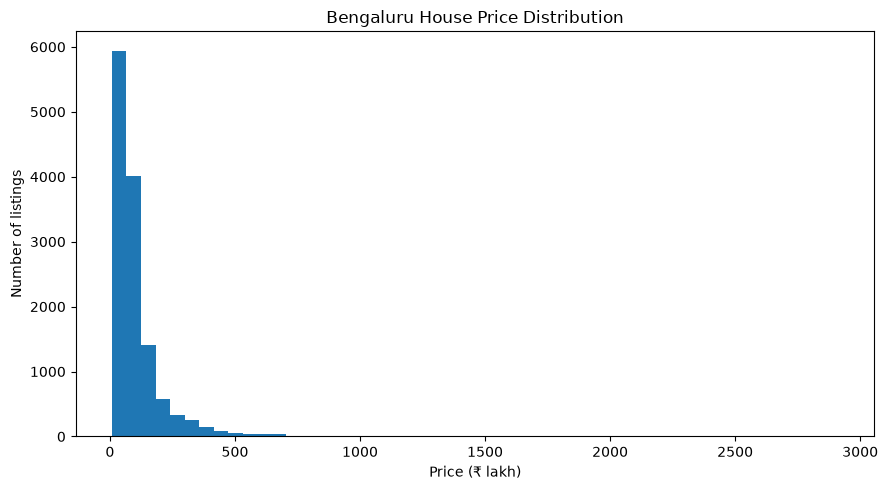

In [4]:
plt.figure(figsize=(9, 5))
plt.hist(df["price"], bins=50)
plt.title("Bengaluru House Price Distribution")
plt.xlabel("Price (₹ lakh)")
plt.ylabel("Number of listings")
plt.tight_layout()
plt.show()

## 5. Train and evaluate model

The model uses only the same four input fields shown in the app: location, total square feet, bathrooms, and BHK. Location is one-hot encoded inside a scikit-learn pipeline, so the app must pass the original feature names.

In [5]:
feature_columns = ["location", "total_sqft", "bath", "BHK"]
X = df[feature_columns].copy()
y = df["price"].copy()  # Bengaluru dataset prices are commonly expressed in ₹ lakh.

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

numeric_features = ["total_sqft", "bath", "BHK"]
categorical_features = ["location"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=250,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"Test MAE: ₹{mae:.2f} lakh")
print(f"Test RMSE: ₹{rmse:.2f} lakh")
print(f"Test R²: {r2:.4f}")

Test MAE: ₹33.71 lakh
Test RMSE: ₹90.55 lakh
Test R²: 0.5933


## 6. Inspect sample predictions

In [6]:
comparison = X_test.copy()
comparison["actual_price_lakh"] = y_test
comparison["predicted_price_lakh"] = predictions
comparison["absolute_error_lakh"] = (comparison["actual_price_lakh"] - comparison["predicted_price_lakh"]).abs()
display(comparison.head(10))

,location,total_sqft,bath,BHK,actual_price_lakh,predicted_price_lakh,absolute_error_lakh
832,7th Phase JP Nagar,1450.0,2.0,3,100.00,89.819590,10.180410
12733,Ambedkar Nagar,1850.0,4.0,3,121.00,127.288694,6.288694
7926,Doddakannelli,780.0,3.0,3,75.00,91.768692,16.768692
10576,Electronic City,550.0,1.0,1,27.00,16.028078,10.971922
4322,Rajarajeshwari nagar,1410.0,2.0,3,45.12,57.376273,12.256273
2661,Bidadi,1600.0,2.0,2,110.00,87.877047,22.122953
1412,Chikka Banaswadi,1093.0,2.0,2,65.00,44.068767,20.931233
2979,Electronic City,1128.0,2.0,2,65.00,65.125175,0.125175
1523,Chandapura,1500.0,2.0,2,60.00,90.510082,30.510082
10891,Bharathi Nagar,1120.0,2.0,2,39.29,52.022361,12.732361


## 7. Export artifacts for Streamlit app

Run this cell after training. It creates `random_forest_house_price_model.pkl` and `dataset.pkl` in the notebook's current working directory. Keep the app and these files in the same project folder.

In [7]:
import joblib

# Compress and save the model using joblib instead of standard pickle
joblib.dump(model, "random_forest_house_price_model.pkl", compress=3)

# The app uses this only to populate the location dropdown.
with open("dataset.pkl", "wb") as f:
    pickle.dump(df[["location"]].drop_duplicates().reset_index(drop=True), f)

print("Saved compressed random_forest_house_price_model.pkl")
print("Saved dataset.pkl")

Saved compressed random_forest_house_price_model.pkl
Saved dataset.pkl
